# Lab color histograms: ROI → features → matching on training data

Full pipeline on the **same 12 official-training images** as `common/ROI_refinement/results/images`:

1. **ROI** - V4 `green_blue_50` coarse ROIs, then FINAL (S2 + S1 boundary) local windows (`detection.detection.generate_candidates`).
2. **Features** - `lab_histogram` on every window (`detection.detection.extract_candidate_features`), extracted only after ROI.
3. **References** - class-mean Lab histograms of training GT boxes (`detection.feature_matching.build_references`).
4. **Thresholds** - per class on the validation split, GT boxes vs background pipeline windows (`calibrate_thresholds`, balanced accuracy).
5. **Matching + NMS** - nearest class with D3 = sum (a-b)^2 / max(a,b) (`chi_square_max`), then same-class NMS.
6. **Evaluation** - ROI coverage (as in ROI_refinement) + detection TP/FP/FN (`detection.evaluation`).

Only code from `common/` and `detection/` runs the pipeline. This notebook only adds data selection, plotting and report writing.
Outputs go to `color_results/lab_results/` with the same layout as `common/ROI_refinement/results/`.

In [1]:
from pathlib import Path
import sys, json, time, html
ROOT = Path.cwd()
while not (ROOT/'common').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common.dataset import DATASET_DIR, SPLIT_FILE, split_data
from common.ROI.v4.evaluate_rois import read_training, measure_gt, draw_boxes
from common.ROI.v4.generate_rois import load_config as load_v4
from common.ROI_refinement.generate_windows import load_config as load_windows
from common.ROI_refinement.evaluate import metrics
from detection.detection import load_image, generate_candidates, extract_candidate_features, match_candidates
from detection.feature_extract import extract_features
from detection.feature_matching import build_references, calibrate_thresholds, postprocess_detections
from detection.evaluation import load_ground_truth, evaluate_dataset, generate_report
%matplotlib inline

In [2]:
SPACE = 'Lab'
FEATURE = 'lab_histogram'
METRIC = 'chi_square_max'      # D3, the project's only distance
METHOD = 'FINAL'               # selected ROI refinement (S2 + S1 boundary fallback)
N_REFERENCE_IMAGES = 300       # training-split images whose GT boxes build the references
N_VALIDATION_IMAGES = 120      # validation-split images used to calibrate thresholds
BACKGROUND_PER_IMAGE = 50      # GT-free pipeline windows per validation image
NMS_IOU = .5
EVAL_IOU = .5
SEED = 42
COARSE_DIR = ROOT/'common/ROI/v4/result_official'   # lists the 12 images in ROI_refinement/results
OUTPUT = ROOT/'color_results'/f'{SPACE.lower()}_results'
(OUTPUT/'images').mkdir(parents=True, exist_ok=True)
(OUTPUT/'windows').mkdir(exist_ok=True)

feature_config = {'names': [FEATURE], 'metric': METRIC}
roi_config = {'v4': load_v4(), 'windows': load_windows(), 'method': METHOD, 'apply_denoise': True}
WORK_W, WORK_H = roi_config['v4']['work_size']

## 1. Data

The 12 evaluation images are the official-training images in `ROI_refinement/results`. They are removed from the reference and calibration pools, so no evaluation image is used to fit references or thresholds.

In [3]:
annotations = pd.read_parquet(DATASET_DIR/'annotations.parquet')
split = json.loads(SPLIT_FILE.read_text()) if SPLIT_FILE.exists() else split_data(annotations)
table = read_training(DATASET_DIR)   # canonical (deduplicated) official-train GT
by_image = dict(tuple(table.groupby('image_path', sort=False)))
coarse_rows = [json.loads(line) for line in (COARSE_DIR/'proposals.jsonl').read_text().splitlines()]
eval_images = [row['image'] for row in coarse_rows]

rng = np.random.default_rng(SEED)
reference_pool = sorted(set(split['train']) - set(eval_images))
validation_pool = sorted(set(split['validation']) - set(eval_images))
reference_images = sorted(map(str, rng.choice(reference_pool, N_REFERENCE_IMAGES, replace=False)))
validation_images = sorted(map(str, rng.choice(validation_pool, N_VALIDATION_IMAGES, replace=False)))


def gt_boxes(path):
    """Labels and original-image half-open xyxy GT of one image."""
    group = by_image[path]
    boxes = group[['x', 'y', 'w', 'h']].to_numpy().copy()
    boxes[:, 2:] += boxes[:, :2]
    return group.label.to_numpy(), boxes


def to_work(boxes, shape):
    """Original xyxy -> 1440x930 working xyxy, the space of V4 and the windows."""
    h, w = shape[:2]
    return np.clip(boxes*[WORK_W/w, WORK_H/h, WORK_W/w, WORK_H/h], 0, [WORK_W, WORK_H, WORK_W, WORK_H])


print(f'eval images: {len(eval_images)} | reference pool: {len(reference_pool)} -> {len(reference_images)} '
      f'| validation pool: {len(validation_pool)} -> {len(validation_images)}')

eval images: 12 | reference pool: 2288 -> 300 | validation pool: 571 -> 120


## 2. Training references

Each training GT box is cut from the same resized (1440x930) and denoised image that V4 uses, so references and windows share preprocessing. The reference for each class is its mean Lab histogram.

In [4]:
started = time.perf_counter()
train_features, train_labels = [], []
for path in reference_images:
    labels, boxes = gt_boxes(path)
    result = extract_features(load_image(DATASET_DIR/path), boxes, FEATURE, work_size=(WORK_W, WORK_H),
                              boxes_space='original', apply_denoise=roi_config['apply_denoise'])
    valid = result['valid_rows'][FEATURE]
    train_features.append(result['features'][FEATURE][valid])
    train_labels += list(labels[valid])
references = build_references(np.vstack(train_features), train_labels, strategy='mean')
references['feature_config'] = feature_config
reference_counts = pd.Series(train_labels).value_counts().sort_index()
print(f'{len(train_labels)} training GT boxes in {time.perf_counter()-started:.0f}s')
reference_counts.rename('training GT boxes').to_frame()

1483 training GT boxes in 144s


,training GT boxes
cone,762
roadworks,185
vertical_pannel,536


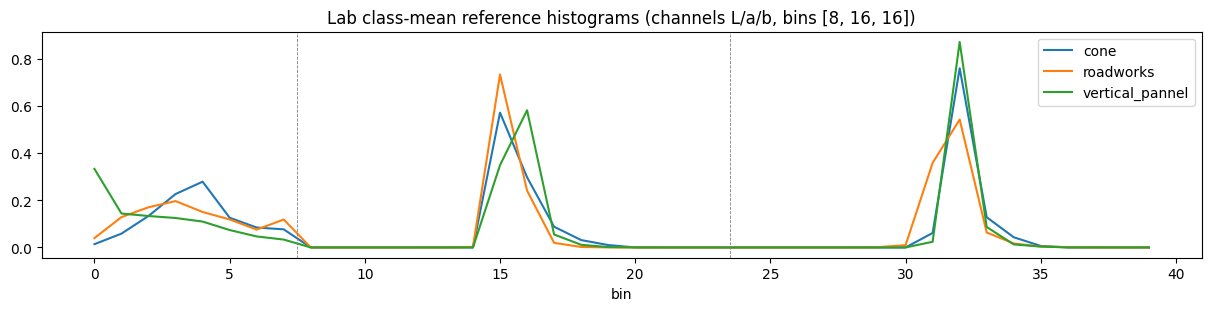

In [5]:
fig, ax = plt.subplots(figsize=(12, 3), layout='constrained')
for label, vector in zip(references['labels'], references['features']):
    ax.plot(vector, label=label)
bins = result['config']['histogram_bins'][FEATURE]
for edge in np.cumsum(bins)[:-1]:
    ax.axvline(edge-.5, color='gray', lw=.6, ls='--')
ax.set_title(f'{SPACE} class-mean reference histograms (channels {"/".join(SPACE)}, bins {bins})')
ax.set_xlabel('bin'); ax.legend()
fig.savefig(OUTPUT/'references.png', dpi=120)
plt.show()

## 3. Validation thresholds

Positives are the validation GT boxes. Background examples are windows from the actual ROI pipeline that do not touch any GT box. The GT is not exhaustive, so a few of these windows may contain unlabeled objects. Thresholds maximize per-class balanced accuracy under the nearest-class-first rule.

In [6]:
started = time.perf_counter()
val_features, val_labels = [], []
for path in validation_images:
    image = load_image(DATASET_DIR/path)
    labels, boxes = gt_boxes(path)
    candidates = generate_candidates(image, roi_config)
    gt_work, windows = to_work(boxes, image.shape), candidates['boxes']
    touches = (np.minimum(windows[:, None, 2:], gt_work[None, :, 2:]) >
               np.maximum(windows[:, None, :2], gt_work[None, :, :2])).all(axis=2).any(axis=1)
    free = np.flatnonzero(~touches)
    background = windows[rng.choice(free, min(BACKGROUND_PER_IMAGE, len(free)), replace=False)]
    result = extract_features(candidates['work_image_bgr'], np.vstack([gt_work, background]), FEATURE,
                              boxes_space='working', apply_denoise=False)
    valid = result['valid_rows'][FEATURE]
    val_features.append(result['features'][FEATURE][valid])
    val_labels += list(np.r_[labels, ['Background']*len(background)][valid])
calibration = calibrate_thresholds(references['features'], references['labels'], np.vstack(val_features),
                                   val_labels, metric=METRIC, mode='balanced_accuracy')
print(f'{len(val_labels)} validation regions in {time.perf_counter()-started:.0f}s')
print(pd.Series(val_labels).value_counts().to_dict())
pd.DataFrame(calibration['per_class']).T.assign(threshold=pd.Series(calibration['thresholds']))

6531 validation regions in 88s
{'Background': 5950, 'cone': 265, 'vertical_pannel': 242, 'roadworks': 74}


,target_count,negative_count,correctly_nearest_positive_count,true_positive,false_positive,target_retention,false_positive_rate,background_acceptance,threshold
cone,265.0,6266.0,177.0,164.0,785.0,0.618868,0.125279,0.110420,1.811822
roadworks,74.0,6457.0,52.0,52.0,199.0,0.702703,0.030819,0.028739,1.306722
vertical_pannel,242.0,6289.0,103.0,103.0,463.0,0.425620,0.073621,0.071597,1.845380


## 4. ROI → features → matching on the 12 training images

These are the same stages as `detection.detection.detect_image`, called one by one so that the windows and match arrays can be saved for the ROI analysis.

In [7]:
runs, predictions = {}, {}
for number, path in enumerate(eval_images):
    t0 = time.perf_counter()
    image = load_image(DATASET_DIR/path)
    t1 = time.perf_counter()
    candidates = generate_candidates(image, roi_config)
    t2 = time.perf_counter()
    matrix = extract_candidate_features(candidates, feature_config)
    t3 = time.perf_counter()
    matches = match_candidates(matrix, references, calibration['thresholds'], feature_config)
    t4 = time.perf_counter()
    h, w = image.shape[:2]
    boxes = candidates['boxes'].astype(float)*[w/WORK_W, h/WORK_H, w/WORK_W, h/WORK_H]
    final = postprocess_detections(boxes, matches, iou_threshold=NMS_IOU)
    t5 = time.perf_counter()
    predictions[path] = dict(image_id=path, image_size=[w, h], detections=[
        dict(bbox=[float(x0), float(y0), float(x1-x0), float(y1-y0)], **{'class': str(label)},
             distance=float(distance), accepted=True, candidate_index=int(source))
        for (x0, y0, x1, y1), label, distance, source in
        zip(final['boxes'], final['labels'], final['distances'], final['source_indices'])])
    artifact = f'windows/{number:03d}_{Path(path).stem}_{METHOD}.npz'
    np.savez_compressed(OUTPUT/artifact, work_boxes=candidates['boxes'], accepted=matches['accepted'],
                        labels=matches['labels'].astype(str), nearest_classes=matches['nearest_classes'].astype(str),
                        distances=matches['distances'], final_indices=final['source_indices'])
    runs[path] = dict(number=number, shape=image.shape, work=candidates['work_image_bgr'], coarse=candidates['coarse_boxes'],
                      windows=candidates['boxes'], matches=matches, final=final['source_indices'], artifact=artifact,
                      coarse_matches_frozen=np.array_equal(np.reshape(candidates['coarse_boxes'], (-1, 4)),
                                                           np.reshape(coarse_rows[number]['work_boxes'], (-1, 4))),
                      runtime=dict(load=t1-t0, candidates=t2-t1, extraction=t3-t2, matching=t4-t3, postprocessing=t5-t4))
    print(f'{number+1}/{len(eval_images)}: {len(candidates["boxes"]):,} windows, '
          f'{int(matches["accepted"].sum()):,} accepted, {len(final["source_indices"])} after NMS ({t5-t0:.1f}s)')
assert all(run['coarse_matches_frozen'] for run in runs.values()), 'Live V4 differs from the frozen ROI_refinement input.'

1/12: 135 windows, 71 accepted, 42 after NMS (0.6s)


2/12: 30,198 windows, 4,695 accepted, 2469 after NMS (1.8s)


3/12: 27,384 windows, 9,913 accepted, 4697 after NMS (2.2s)


4/12: 4,993 windows, 918 accepted, 466 after NMS (0.7s)


5/12: 48,382 windows, 21,494 accepted, 10511 after NMS (5.1s)


6/12: 26,056 windows, 3,752 accepted, 1998 after NMS (1.6s)


... (2 outputs left out)

9/12: 0 windows, 0 accepted, 0 after NMS (0.5s)


10/12: 33,998 windows, 5,492 accepted, 2849 after NMS (2.0s)


11/12: 8,828 windows, 1,133 accepted, 538 after NMS (0.9s)


12/12: 47,305 windows, 12,765 accepted, 6318 after NMS (4.3s)


## 5. Evaluation

Every GT box gets the same ROI coverage metrics as `ROI_refinement/results`: coarse V4 coverage, then the best FINAL window. Two feature-stage columns are added: coverage by the windows that matching accepted, and whether a final detection matches the box (same class, IoU >= 0.5, greedy in distance order, from `detection.evaluation`).

In [8]:
truth = load_ground_truth(DATASET_DIR/'annotations.parquet', image_ids=eval_images)
report = evaluate_dataset(list(predictions.values()), truth, iou_threshold=EVAL_IOU)
generate_report(report, OUTPUT/'detection')

method = f'{METHOD}+{FEATURE}'
object_rows, count_rows = [], []
for path, run in runs.items():
    labels, boxes = gt_boxes(path)
    assert np.allclose([g['bbox'] for g in truth[path]], np.c_[boxes[:, :2], boxes[:, 2:]-boxes[:, :2]])
    image_report = report['per_image'][path]
    detected = {m['gt_index']: m['iou'] for m in image_report['matches']}
    accepted = run['matches']['accepted']
    gt_work = to_work(boxes, run['shape'])
    run['gt'], run['report'] = gt_work, image_report
    for index, (label, box) in enumerate(zip(labels, gt_work)):
        upper = measure_gt(box, run['coarse'])
        row = metrics(box, run['windows'])
        kept = measure_gt(box, run['windows'][accepted])
        same = measure_gt(box, run['windows'][accepted & (run['matches']['labels'] == label)])
        object_rows.append(dict(image=path, object_index=index, source_label=label, method=method,
            coarse_covered_95=upper['covered_95'], coarse_covered_100=upper['covered_100'],
            coarse_area_ratio_95=upper['area_ratio_95'], gt_work_xyxy=json.dumps(box.tolist()), **row,
            accepted_covered_95=kept['covered_95'], accepted_best_iou=kept['best_iou'],
            accepted_same_class_iou_05=same['best_iou'] >= EVAL_IOU,
            detected=index in detected, detection_iou=detected.get(index, 0.)))
    count_rows.append(dict(image=path, method=method, coarse_roi_count=len(run['coarse']), windows=len(run['windows']),
        accepted=int(accepted.sum()), final_detections=len(run['final']),
        TP=image_report['TP'], FP=image_report['FP'], FN=image_report['FN'],
        **{f'runtime_{k}_seconds': v for k, v in run['runtime'].items()},
        runtime_seconds=sum(run['runtime'].values()), artifact=run['artifact']))
objects, counts = pd.DataFrame(object_rows), pd.DataFrame(count_rows)
objects.to_csv(OUTPUT/'per_gt.csv', index=False)
counts.to_csv(OUTPUT/'per_image.csv', index=False)


def summarize(group):
    """ROI_refinement summary columns, then the feature-stage columns."""
    return dict(gt_count=len(group), covered_95=int(group.covered_95.sum()), covered_100=int(group.covered_100.sum()),
        coverage_95=float(group.covered_95.mean()), iou_05=float((group.best_iou >= .5).mean()),
        coarse_covered_95=int(group.coarse_covered_95.sum()),
        conditional_coverage_95=float(group.loc[group.coarse_covered_95, 'covered_95'].mean()),
        lost_coarse_covered_95=int((group.coarse_covered_95 & ~group.covered_95).sum()),
        matched_coarse_ratio_95_median=float(group.loc[group.covered_95, 'coarse_area_ratio_95'].median()),
        compact_ratio_95_median=float(group.area_ratio_95.median()), compact_ratio_95_p90=float(group.area_ratio_95.quantile(.9)),
        accepted_covered_95=int(group.accepted_covered_95.sum()),
        lost_by_matching_95=int((group.covered_95 & ~group.accepted_covered_95).sum()),
        accepted_same_class_iou_05=int(group.accepted_same_class_iou_05.sum()),
        detected=int(group.detected.sum()))


overall = report['overall']
summary = pd.DataFrame([dict(method=method, **summarize(objects), mean_windows=float(counts.windows.mean()),
    mean_accepted=float(counts.accepted.mean()), mean_final_detections=float(counts.final_detections.mean()),
    TP=overall['TP'], FP=overall['FP'], FN=overall['FN'], precision=overall['precision'],
    recall=overall['recall'], f1=overall['f1'], mean_runtime_seconds=float(counts.runtime_seconds.mean()))])
by_label = pd.DataFrame([dict(method=method, source_label=label, **summarize(group),
    **{k: report['per_class'].get(label, {}).get(k) for k in ('TP', 'FP', 'FN', 'precision', 'recall', 'f1')})
    for label, group in objects.groupby('source_label')])
summary.to_csv(OUTPUT/'summary.csv', index=False)
by_label.to_csv(OUTPUT/'by_label.csv', index=False)
summary.T

/Users/malikashahi/.local/share/virtualenvs/mitcarbon-VITON-NWGeUqUA/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,0
method,FINAL+lab_histogram
gt_count,73
covered_95,34
covered_100,32
coverage_95,0.465753
iou_05,0.438356
coarse_covered_95,36
conditional_coverage_95,0.944444
lost_coarse_covered_95,2
matched_coarse_ratio_95_median,271.722632


In [9]:
by_label.set_index('source_label').T

source_label,cone,roadworks,vertical_pannel
method,FINAL+lab_histogram,FINAL+lab_histogram,FINAL+lab_histogram
gt_count,7,3,63
covered_95,7,0,27
covered_100,7,0,25
coverage_95,1.0,0.0,0.428571
iou_05,1.0,0.666667,0.365079
coarse_covered_95,7,1,28
conditional_coverage_95,1.0,0.0,0.964286
lost_coarse_covered_95,0,1,1
matched_coarse_ratio_95_median,493.424529,NaN,252.099191


In [10]:
pd.Series(report['failure_counts'], name='unmatched predictions (all FP)').to_frame()

,unmatched predictions (all FP)
background,43470
localization,3766
wrong_class,6
duplicate,3


## 6. Figures

Per-image figures follow the `ROI_refinement/results/images` style, on the 1440x930 working image:
- **Left:** frozen V4 coarse ROIs (green), GT (cyan).
- **Middle:** density of accepted window centers. GT outline shows coverage by accepted windows: cyan >= 95%, gold partial, red none.
- **Right:** final detections after NMS (green TP, red FP). GT cyan if detected, gold if missed.

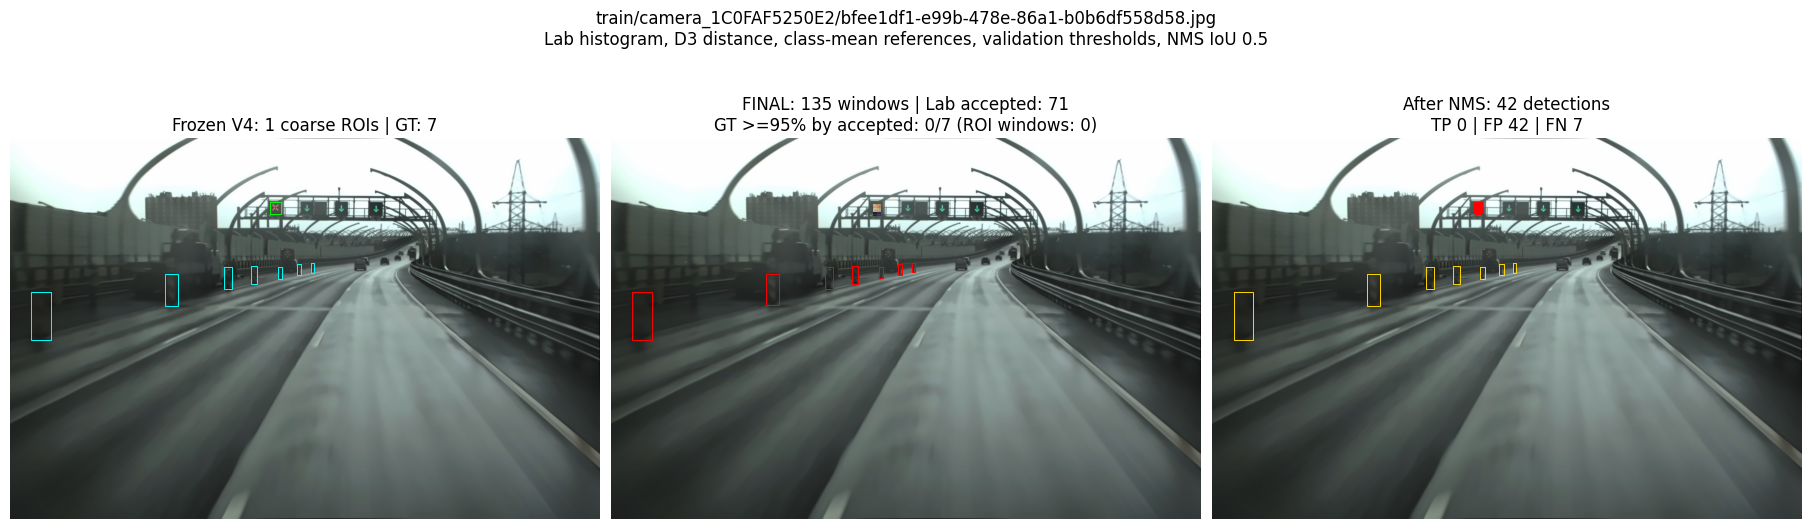

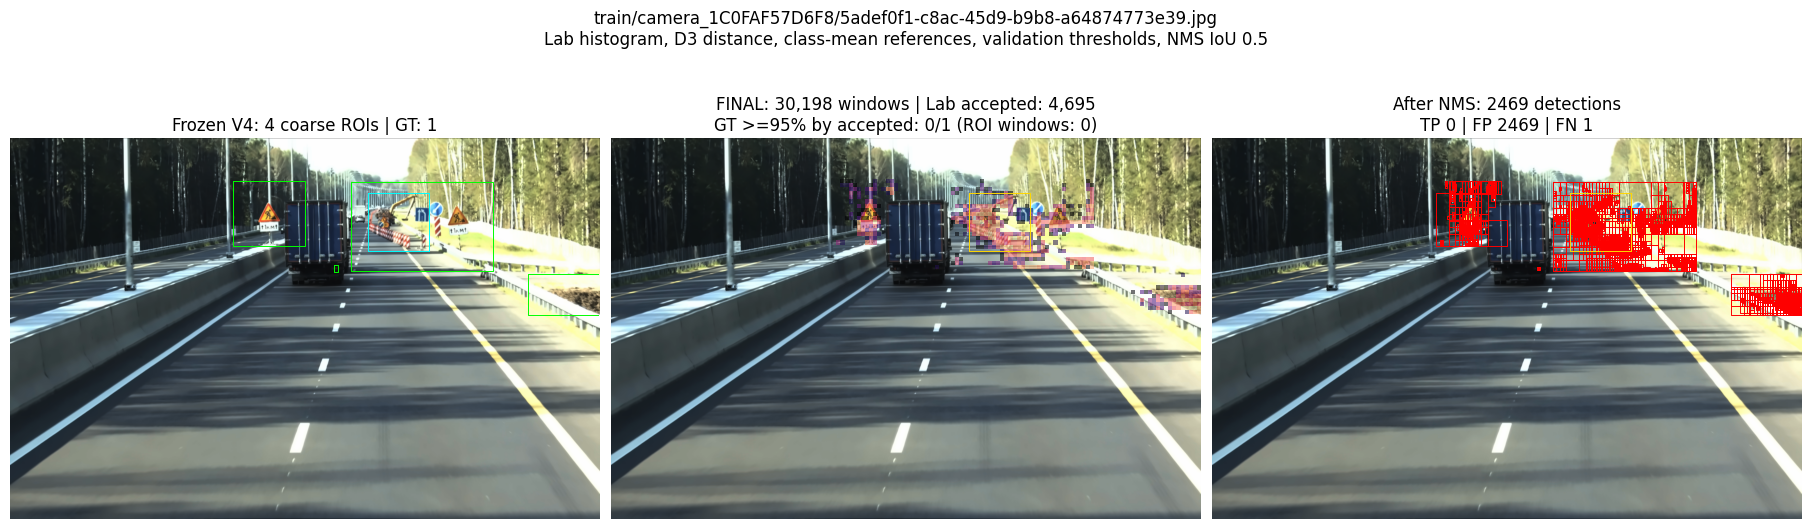

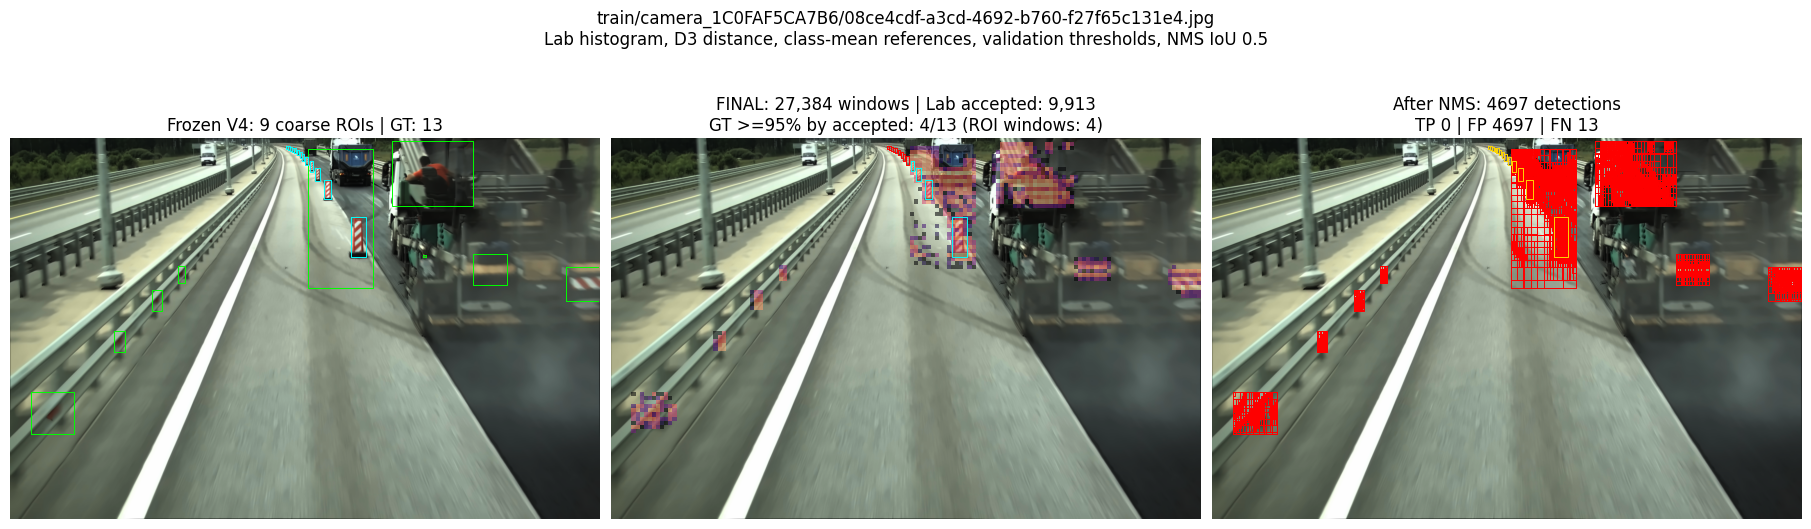

In [11]:
def plot_scene(run, output, title):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')
    rgb = cv2.cvtColor(run['work'], cv2.COLOR_BGR2RGB)
    for ax in axes:
        ax.imshow(rgb); ax.axis('off')
    gt, windows, matches = run['gt'], run['windows'], run['matches']
    rows = objects[objects.image == run['path']]
    draw_boxes(axes[0], run['coarse'], 'lime'); draw_boxes(axes[0], gt, 'cyan')
    axes[0].set_title(f'Frozen V4: {len(run["coarse"])} coarse ROIs | GT: {len(gt)}')
    accepted = windows[matches['accepted']]
    if len(accepted):
        centers = (accepted[:, :2]+accepted[:, 2:])/2
        density, _, _ = np.histogram2d(centers[:, 1], centers[:, 0], bins=(93, 144), range=[[0, WORK_H], [0, WORK_W]])
        axes[1].imshow(np.ma.masked_where(density == 0, np.log1p(density)), extent=(0, WORK_W, WORK_H, 0), cmap='magma', alpha=.55)
    for box, (_, row) in zip(gt, rows.iterrows()):
        draw_boxes(axes[1], box[None], 'cyan' if row.accepted_covered_95 else 'gold' if row.accepted_best_iou > 0 else 'red')
    axes[1].set_title(f'{METHOD}: {len(windows):,} windows | {SPACE} accepted: {len(accepted):,}\n'
                      f'GT >=95% by accepted: {int(rows.accepted_covered_95.sum())}/{len(gt)} (ROI windows: {int(rows.covered_95.sum())})')
    final = windows[run['final']]
    tp = np.zeros(len(final), bool)
    tp[[m['prediction_index'] for m in run['report']['matches']]] = True
    draw_boxes(axes[2], final[~tp], 'red'); draw_boxes(axes[2], final[tp], 'lime')
    for box, (_, row) in zip(gt, rows.iterrows()):
        draw_boxes(axes[2], box[None], 'cyan' if row.detected else 'gold')
    axes[2].set_title(f'After NMS: {len(final)} detections\nTP {run["report"]["TP"]} | FP {run["report"]["FP"]} | FN {run["report"]["FN"]}')
    fig.suptitle(title+f'\n{SPACE} histogram, D3 distance, class-mean references, validation thresholds, NMS IoU {NMS_IOU}')
    fig.savefig(output, dpi=120)
    return fig


gallery = []
for path, run in runs.items():
    run['path'] = path
    filename = f'{run["number"]:03d}_{Path(path).stem}.png'
    fig = plot_scene(run, OUTPUT/'images'/filename, path)
    gallery.append((path, filename))
    if run['number'] < 3:
        plt.show()
    plt.close(fig)

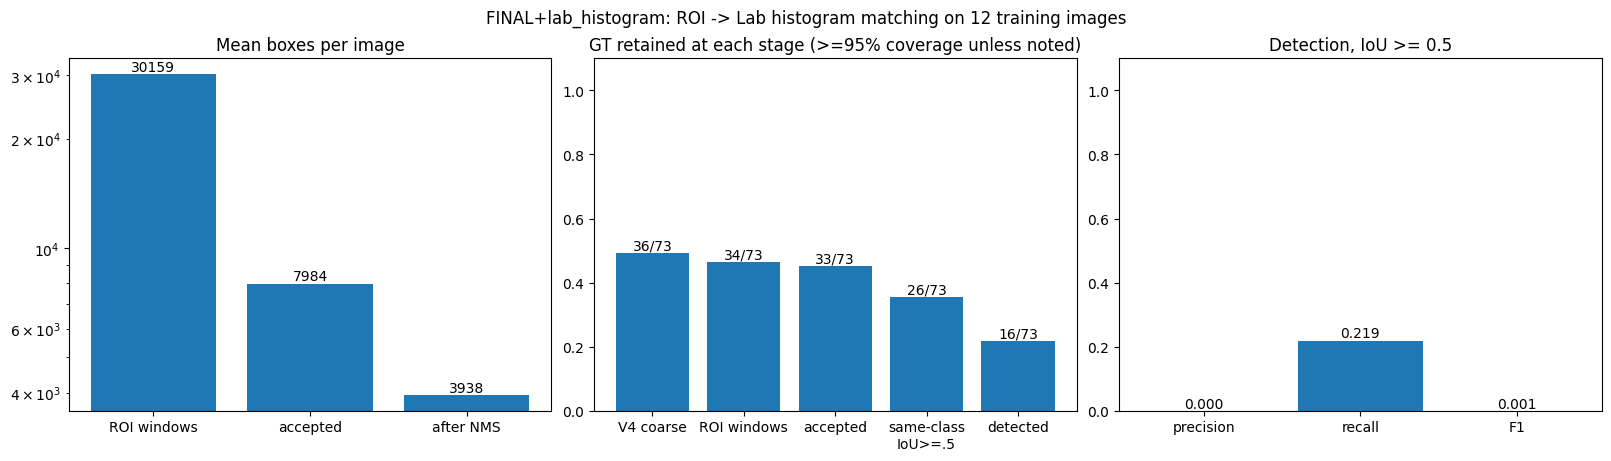

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout='constrained')
row = summary.iloc[0]
stages = [('ROI windows', row.mean_windows), ('accepted', row.mean_accepted), ('after NMS', row.mean_final_detections)]
bars = axes[0].bar([s for s, _ in stages], [v for _, v in stages]); axes[0].set_yscale('log')
axes[0].bar_label(bars, fmt='%.0f'); axes[0].set_title('Mean boxes per image')
coverage = [('V4 coarse', row.coarse_covered_95), ('ROI windows', row.covered_95),
            ('accepted', row.accepted_covered_95), ('same-class\nIoU>=.5', row.accepted_same_class_iou_05), ('detected', row.detected)]
bars = axes[1].bar([s for s, _ in coverage], [v/row.gt_count for _, v in coverage])
axes[1].bar_label(bars, labels=[f'{int(v)}/{row.gt_count}' for _, v in coverage]); axes[1].set_ylim(0, 1.1)
axes[1].set_title('GT retained at each stage (>=95% coverage unless noted)')
bars = axes[2].bar(['precision', 'recall', 'F1'], [row.precision, row.recall, row.f1])
axes[2].bar_label(bars, fmt='%.3f'); axes[2].set_ylim(0, 1.1); axes[2].set_title(f'Detection, IoU >= {EVAL_IOU}')
fig.suptitle(f'{method}: ROI -> {SPACE} histogram matching on {len(eval_images)} training images')
fig.savefig(OUTPUT/'summary.png', dpi=150)
plt.show()

## 7. Report files

`summary.json`, `model.json` (references, thresholds and configs in the format `python -m detection.detection --model` reads), `analysis.md` and `index.html`.

In [13]:
def plain(value):
    return value.tolist() if hasattr(value, 'tolist') else str(value)


row = summary.iloc[0]
summary_json = dict(scope='In-sample development on 12 official-training images (same as ROI_refinement/results); '
                          'references and thresholds fitted on other training/validation images; official test untouched',
    feature_config=feature_config, roi_method=METHOD, color_space=SPACE, nms_iou=NMS_IOU, evaluation_iou=EVAL_IOU,
    reference_strategy=references['strategy'], reference_images=reference_images, validation_images=validation_images,
    reference_counts=reference_counts.to_dict(), calibration=calibration, evaluation_images=eval_images,
    coarse_source=str(COARSE_DIR), live_v4_matches_frozen=bool(all(r['coarse_matches_frozen'] for r in runs.values())),
    detection=dict(overall=report['overall'], per_class=report['per_class'], failure_counts=report['failure_counts']),
    summary=summary.to_dict('records')[0],
    timing='Per-image candidates (V4 + windows incl. resize/denoise), extraction, matching, NMS; excludes reference/threshold fitting, plotting and I/O.')
(OUTPUT/'summary.json').write_text(json.dumps(summary_json, indent=2, default=plain))
model = dict(feature_config=feature_config, roi_config=roi_config, thresholds=calibration['thresholds'],
             references=dict(features=references['features'].tolist(), labels=references['labels'].tolist(),
                             strategy=references['strategy'], feature_config=feature_config))
(OUTPUT/'model.json').write_text(json.dumps(model, indent=2, default=plain))

per_class = '; '.join(f"{label}: P {v['precision']:.3f} R {v['recall']:.3f} (TP {v['TP']}, FP {v['FP']}, FN {v['FN']})"
                      for label, v in report['per_class'].items())
failures = ', '.join(f'{k} {v}' for k, v in sorted(report['failure_counts'].items(), key=lambda kv: -kv[1]))
thresholds = ', '.join(f'{k} {v:.3f}' for k, v in calibration['thresholds'].items())
analysis = (f"{SPACE} histograms ({FEATURE}, bins {result['config']['histogram_bins'][FEATURE]}) were extracted on every {METHOD} window "
    f"after V4 coarse ROI generation, on the same {len(eval_images)} training images and {int(row.gt_count)} canonical GT boxes as ROI_refinement. "
    f"ROI windows cover {int(row.covered_95)}/{int(row.gt_count)} GT at >=95% (V4 ceiling {int(row.coarse_covered_95)}). "
    f"Matching with D3 against class-mean references and validation thresholds ({thresholds}) accepts "
    f"{row.mean_accepted:,.0f} of {row.mean_windows:,.0f} windows per image ({row.mean_accepted/row.mean_windows:.1%}); "
    f"accepted windows still cover {int(row.accepted_covered_95)} GT at >=95% ({int(row.lost_by_matching_95)} lost by matching), "
    f"and {int(row.accepted_same_class_iou_05)} GT have a same-class accepted window with IoU >= 0.5. "
    f"After same-class NMS at IoU {NMS_IOU}: {row.mean_final_detections:,.1f} detections per image, "
    f"TP {int(row.TP)}, FP {int(row.FP)}, FN {int(row.FN)}; precision {row.precision:.3f}, recall {row.recall:.3f}, F1 {row.f1:.3f}. "
    f"Per class: {per_class}. Unmatched-prediction reasons: {failures}. "
    f"References: {len(reference_images)} training-split images ({len(train_labels)} GT boxes); thresholds: {len(validation_images)} "
    f"validation-split images ({calibration['validation_count']} regions, {calibration['background_count']} background windows). "
    "None of the 12 evaluation images was used for fitting, but they are official-training images, so this is development evidence, "
    "not held-out test performance. Background calibration windows come from unannotated regions, and the GT is not exhaustive.")
(OUTPUT/'analysis.md').write_text(f'# {SPACE} histogram matching after ROI refinement\n\n'+analysis+'\n')
body = ['<!doctype html><html lang="en"><meta charset="utf-8"><title>'+SPACE+' ROI feature matching</title>'
        '<style>body{font:16px system-ui;margin:24px}img{width:100%}td,th{padding:7px}</style>',
        f'<h1>{SPACE} histogram matching on {METHOD} ROI windows</h1>',
        '<p>V4 green_blue_50 coarse ROIs, then FINAL rectangular windows, then '+FEATURE+' features, then D3 nearest class-mean reference '
        'with validation thresholds, then same-class NMS. GT is used only for evaluation, never for placing or accepting windows.</p>',
        '<p>'+html.escape(analysis)+'</p>',
        summary.to_html(index=False, float_format=lambda v: f'{v:.3f}'),
        '<h2>By label</h2>', by_label.to_html(index=False, float_format=lambda v: f'{v:.3f}'),
        '<img src="summary.png"><img src="references.png">']
body += [f'<h3>{html.escape(path)}</h3><img loading="lazy" src="images/{filename}">' for path, filename in gallery]
(OUTPUT/'index.html').write_text('\n'.join(body)+'</html>')
print(analysis)
sorted(p.relative_to(OUTPUT).as_posix() for p in OUTPUT.iterdir())

Lab histograms (lab_histogram, bins [8, 16, 16]) were extracted on every FINAL window after V4 coarse ROI generation, on the same 12 training images and 73 canonical GT boxes as ROI_refinement. ROI windows cover 34/73 GT at >=95% (V4 ceiling 36). Matching with D3 against class-mean references and validation thresholds (cone 1.812, roadworks 1.307, vertical_pannel 1.845) accepts 7,984 of 30,159 windows per image (26.5%); accepted windows still cover 33 GT at >=95% (1 lost by matching), and 26 GT have a same-class accepted window with IoU >= 0.5. After same-class NMS at IoU 0.5: 3,938.4 detections per image, TP 16, FP 47245, FN 57; precision 0.000, recall 0.219, F1 0.001. Per class: cone: P 0.000 R 0.286 (TP 2, FP 11265, FN 5); roadworks: P 0.000 R 0.000 (TP 0, FP 2390, FN 3); vertical_pannel: P 0.000 R 0.222 (TP 14, FP 33590, FN 49). Unmatched-prediction reasons: background 43470, localization 3766, wrong_class 6, duplicate 3. References: 300 training-split images (1483 GT boxes); thres

['analysis.md',
 'by_label.csv',
 'detection',
 'images',
 'index.html',
 'model.json',
 'per_gt.csv',
 'per_image.csv',
 'references.png',
 'summary.csv',
 'summary.json',
 'summary.png',
 'windows']